# YOLO Object Detection — CNN Based Complete Project

Yeh project mein hum **YOLOv8** use kar ke ek complete object detection pipeline banayein ge. YOLO (You Only Look Once) ek CNN-based real-time object detector hai jo ek hi forward pass mein image se saare objects detect kar leta hai.

**Kya seekhein ge:**
- CNN architecture kaise features extract karta hai
- YOLO kaise kaam karta hai — bounding boxes, confidence scores, class labels
- YOLOv8 ka pretrained model use karna
- IoU, Precision, Recall, mAP metrics
- Gradio se interactive UI banana aur Hugging Face pe deploy karna

**YOLO Architecture samjho:**
- **Backbone** — CSPDarknet53 se multi-scale features nikalte hain
- **Neck** — PANet se features ko fuse karte hain
- **Head** — Decoupled head jo bbox, score aur class predict karta hai
- **Anchor-Free** — YOLOv8 mein koi predefined anchors nahi hain
- **Single Pass** — poori image ek baar mein process hoti hai, isliye fast hai

> YOLO R-CNN se 100x fast hai kyunke woh do stage mein karta hai, YOLO ek hi baar mein kar leta hai.

---


## Pehle saari libraries install aur import karte hain

In [15]:
# ek ek kar ke install — timeout badhaya hai taake error na aaye
%pip install --timeout 120 numpy Pillow matplotlib pandas -q
%pip install --timeout 120 opencv-python-headless -q
%pip install --timeout 300 torch torchvision --index-url https://download.pytorch.org/whl/cpu -q
%pip install --timeout 300 ultralytics -q
%pip install --timeout 120 gradio -q
print("Saari dependencies install ho gayi hain!")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Saari dependencies install ho gayi hain!


In [16]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import pandas as pd
import os
import urllib.request
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Device: {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")
print("Libraries import ho gayi hain!")

PyTorch Version: 2.10.0+cpu
CUDA Available: False
Device: CPU
Libraries import ho gayi hain!


## Ab pretrained YOLOv8 model load karte hain

YOLOv8 ke different sizes hain — chhota model fast hai, bada model zyada accurate hai:

| Model | Params | mAP@50 | Speed (ms) | Kab use karein |
|-------|--------|--------|------------|----------------|
| YOLOv8n | 3.2M | 37.3 | 1.2 | Mobile / Edge |
| YOLOv8s | 11.2M | 44.9 | 2.1 | Balanced |
| YOLOv8m | 25.9M | 50.2 | 5.0 | Achi accuracy |
| YOLOv8l | 43.7M | 52.9 | 8.1 | Production |
| YOLOv8x | 68.2M | 53.9 | 12.1 | Maximum accuracy |

In [17]:
# YOLOv8s load kar rahe hain — speed aur accuracy ka acha balance hai
model = YOLO('yolov8s.pt')

print(f"Model: YOLOv8s (Small)")
print(f"Task: Object Detection")
print(f"Pretrained on: COCO Dataset (80 classes)")
print(f"Total Parameters: {sum(p.numel() for p in model.model.parameters()):,}")
print(f"Trainable Params: {sum(p.numel() for p in model.model.parameters() if p.requires_grad):,}")
print(f"Device: {next(model.model.parameters()).device}")

# COCO ki saari 80 classes dekho
class_names = model.names
print(f"\nCOCO Classes ({len(class_names)} total):")
for idx, name in class_names.items():
    print(f"  [{idx:2d}] {name}", end="  ")
    if (idx + 1) % 5 == 0:
        print()

Model: YOLOv8s (Small)
Task: Object Detection
Pretrained on: COCO Dataset (80 classes)
Total Parameters: 11,166,560
Trainable Params: 0
Device: cpu

COCO Classes (80 total):
  [ 0] person    [ 1] bicycle    [ 2] car    [ 3] motorcycle    [ 4] airplane  
  [ 5] bus    [ 6] train    [ 7] truck    [ 8] boat    [ 9] traffic light  
  [10] fire hydrant    [11] stop sign    [12] parking meter    [13] bench    [14] bird  
  [15] cat    [16] dog    [17] horse    [18] sheep    [19] cow  
  [20] elephant    [21] bear    [22] zebra    [23] giraffe    [24] backpack  
  [25] umbrella    [26] handbag    [27] tie    [28] suitcase    [29] frisbee  
  [30] skis    [31] snowboard    [32] sports ball    [33] kite    [34] baseball bat  
  [35] baseball glove    [36] skateboard    [37] surfboard    [38] tennis racket    [39] bottle  
  [40] wine glass    [41] cup    [42] fork    [43] knife    [44] spoon  
  [45] bowl    [46] banana    [47] apple    [48] sandwich    [49] orange  
  [50] broccoli    [51] car

## Image load karte hain aur dekhte hain detection se pehle kaisi lagti hai

Already hai: street.jpg
Already hai: zidane.jpg


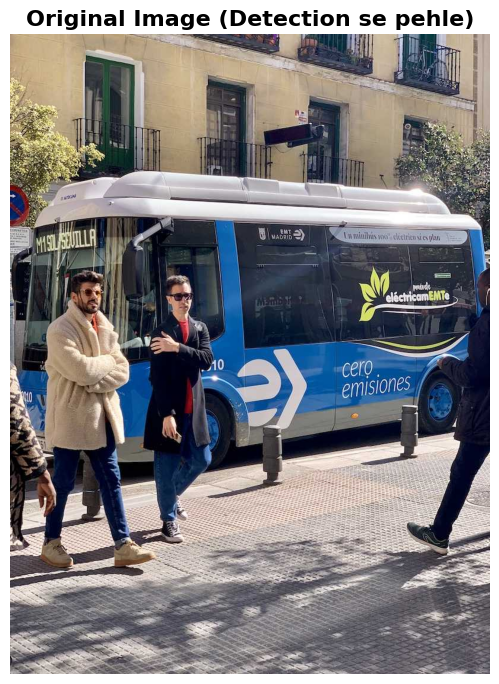


Image Shape: (1080, 810, 3)
Width x Height: 810 x 1080


In [18]:
os.makedirs('sample_images', exist_ok=True)

sample_urls = {
    'street.jpg': 'https://ultralytics.com/images/bus.jpg',
    'zidane.jpg': 'https://ultralytics.com/images/zidane.jpg',
}

for name, url in sample_urls.items():
    filepath = f'sample_images/{name}'
    if not os.path.exists(filepath):
        urllib.request.urlretrieve(url, filepath)
        print(f"Downloaded: {name}")
    else:
        print(f"Already hai: {name}")

img_path = 'sample_images/street.jpg'
img_pil = Image.open(img_path)
img_cv2 = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_cv2, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.imshow(img_rgb)
ax.set_title('Original Image (Detection se pehle)', fontsize=16, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

print(f"\nImage Shape: {img_cv2.shape}")
print(f"Width x Height: {img_cv2.shape[1]} x {img_cv2.shape[0]}")

## Ab YOLO se detection chalate hain

Image model mein daalein ge aur yeh 3 cheezein milein gi:
- **Bounding Boxes** (x1, y1, x2, y2)  object ke around rectangle
- **Confidence Scores**  kitna confident hai ke object hai
- **Class IDs**  kaunsa object hai (80 mein se)

In [19]:
# inference chalate hain — conf 0.25 se zyada waale hi dikhayein ge
results = model(img_path, conf=0.25, iou=0.45, verbose=False)
result = results[0]

print(f"Total Detections: {len(result.boxes)}")
print(f"Inference Speed: {result.speed['inference']:.1f}ms")
print(f"Image Size: {result.orig_shape}")
print(f"Confidence Threshold: 0.25")
print(f"IoU Threshold (NMS): 0.45")

Total Detections: 5
Inference Speed: 245.5ms
Image Size: (1080, 810)
Confidence Threshold: 0.25
IoU Threshold (NMS): 0.45


## Bounding boxes, scores aur class labels extract karte hain DataFrame mein

In [20]:
boxes = result.boxes

# xyxy format mein bounding boxes nikal rahe hain
bbox_xyxy = boxes.xyxy.cpu().numpy()
confidences = boxes.conf.cpu().numpy()
class_ids = boxes.cls.cpu().numpy().astype(int)

# class id se naam nikalo
class_labels = [model.names[cid] for cid in class_ids]

# saari details ek DataFrame mein daal dete hain
detections_df = pd.DataFrame({
    'Class': class_labels,
    'Confidence': [f'{c:.4f}' for c in confidences],
    'Confidence (%)': [f'{c*100:.1f}%' for c in confidences],
    'X1': bbox_xyxy[:, 0].astype(int),
    'Y1': bbox_xyxy[:, 1].astype(int),
    'X2': bbox_xyxy[:, 2].astype(int),
    'Y2': bbox_xyxy[:, 3].astype(int),
    'Width': (bbox_xyxy[:, 2] - bbox_xyxy[:, 0]).astype(int),
    'Height': (bbox_xyxy[:, 3] - bbox_xyxy[:, 1]).astype(int),
})

print(detections_df.to_string(index=True))
print(f"\nTotal Objects: {len(detections_df)}")
print(f"Unique Classes: {detections_df['Class'].nunique()} — {', '.join(detections_df['Class'].unique())}")
print(f"Avg Confidence: {confidences.mean()*100:.1f}%")
print(f"Max: {confidences.max()*100:.1f}% | Min: {confidences.min()*100:.1f}%")

    Class Confidence Confidence (%)   X1   Y1   X2   Y2  Width  Height
0     bus     0.9213          92.1%   14  228  808  748    793     519
1  person     0.8929          89.3%  667  389  809  878    142     488
2  person     0.8865          88.7%   49  401  244  901    194     499
3  person     0.8778          87.8%  222  408  345  860    123     452
4  person     0.6114          61.1%    0  550   65  868     65     318

Total Objects: 5
Unique Classes: 2 — bus, person
Avg Confidence: 83.8%
Max: 92.1% | Min: 61.1%


## Ab image pe bounding boxes draw karte hain  apna custom function banayein ge

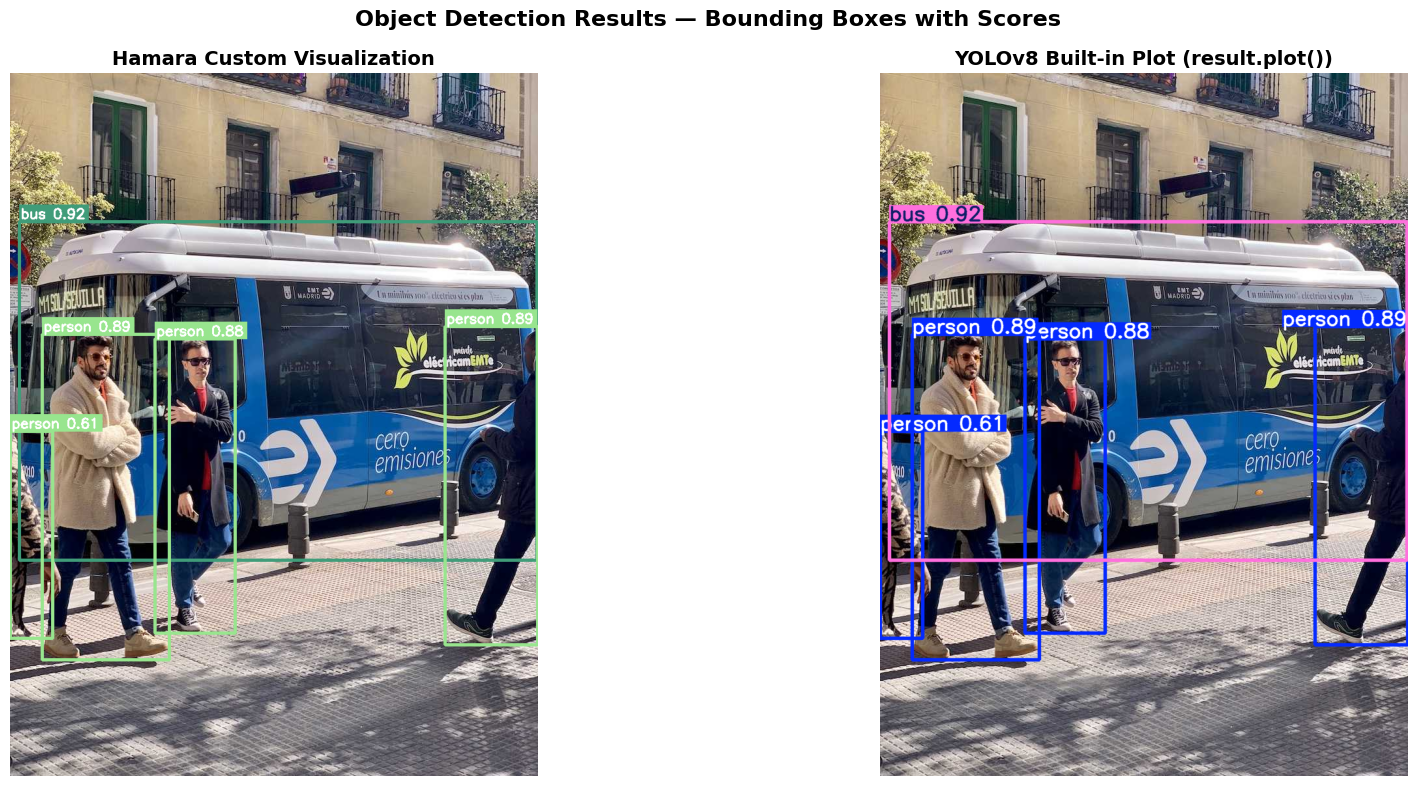

In [21]:
def draw_detections(image, boxes_xyxy, scores, class_ids, class_names, line_width=3):
    """har detection ke liye bbox, label aur score draw karta hai"""
    img = image.copy()
    
    np.random.seed(42)
    colors = {}
    for cid in np.unique(class_ids):
        colors[cid] = tuple(np.random.randint(50, 255, size=3).tolist())
    
    for box, score, cid in zip(boxes_xyxy, scores, class_ids):
        x1, y1, x2, y2 = map(int, box)
        color = colors[cid]
        label = f"{class_names[cid]} {score:.2f}"
        
        cv2.rectangle(img, (x1, y1), (x2, y2), color, line_width)
        
        (text_w, text_h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        cv2.rectangle(img, (x1, y1 - text_h - 10), (x1 + text_w + 5, y1), color, -1)
        cv2.putText(img, label, (x1 + 2, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    
    return img

annotated_custom = draw_detections(img_rgb, bbox_xyxy, confidences, class_ids, model.names)

annotated_builtin = result.plot()
annotated_builtin_rgb = cv2.cvtColor(annotated_builtin, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

axes[0].imshow(annotated_custom)
axes[0].set_title('Hamara Custom Visualization', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(annotated_builtin_rgb)
axes[1].set_title('YOLOv8 Built-in Plot (result.plot())', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Object Detection Results — Bounding Boxes with Scores', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

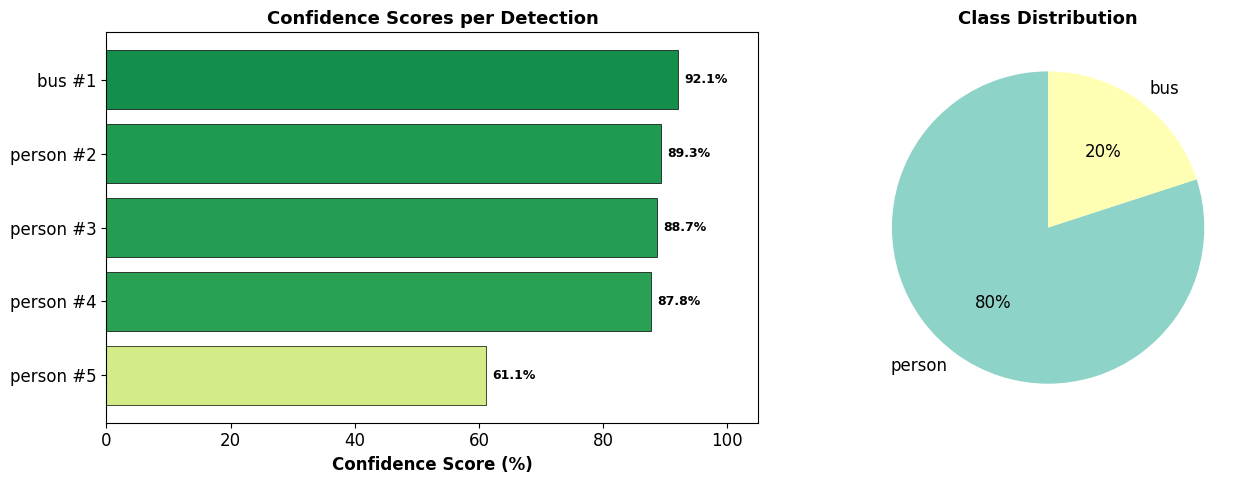

In [22]:
# confidence scores ka chart banate hain — bar aur pie dono

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_bar = plt.cm.RdYlGn(confidences)
bars = axes[0].barh(
    [f"{class_labels[i]} #{i+1}" for i in range(len(class_labels))],
    confidences * 100, color=colors_bar, edgecolor='black', linewidth=0.5
)
axes[0].set_xlabel('Confidence Score (%)', fontweight='bold')
axes[0].set_title('Confidence Scores per Detection', fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 105)
for bar, conf in zip(bars, confidences):
    axes[0].text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f'{conf*100:.1f}%', va='center', fontweight='bold', fontsize=9)
axes[0].invert_yaxis()

class_counts = pd.Series(class_labels).value_counts()
axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.0f%%',
            startangle=90, colors=plt.cm.Set3.colors[:len(class_counts)])
axes[1].set_title('Class Distribution', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## Multiple images pe ek saath detection chalate hain (Batch Inference)

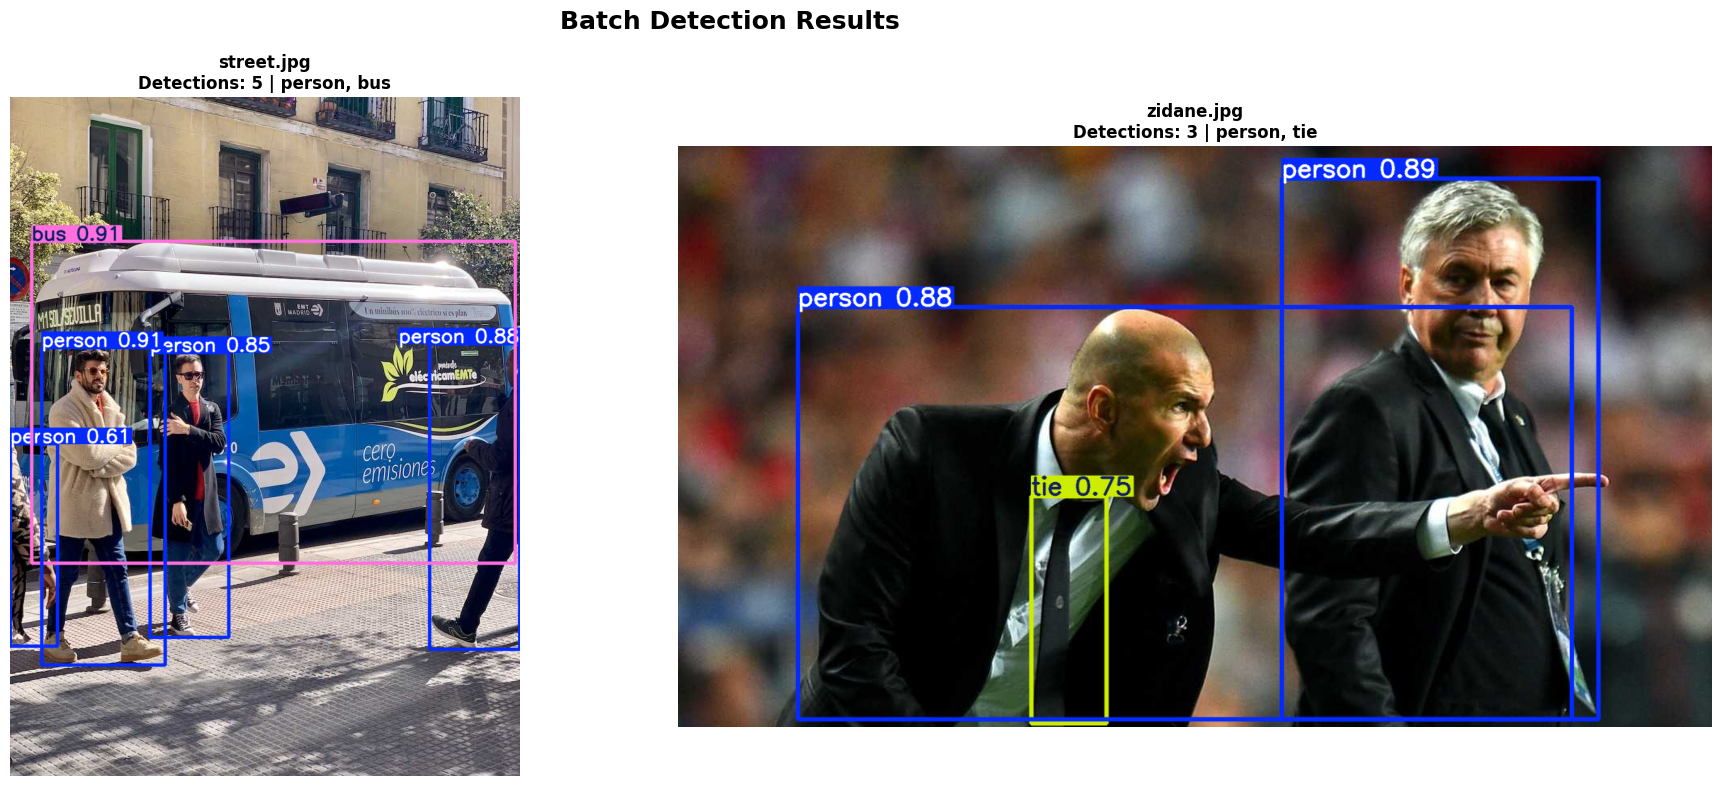


Batch Comparison:
  street.jpg           →  5 detections | Avg Conf: 83.2% | Speed: 287.9ms
  zidane.jpg           →  3 detections | Avg Conf: 83.9% | Speed: 287.9ms


In [23]:
# saari sample images ka list banao
image_paths = [f'sample_images/{f}' for f in os.listdir('sample_images') 
               if f.endswith(('.jpg', '.png', '.jpeg'))]

# ek saath saari images pe detection chala do
batch_results = model(image_paths, conf=0.25, verbose=False)

n_images = len(batch_results)
fig, axes = plt.subplots(1, n_images, figsize=(10 * n_images, 8))
if n_images == 1:
    axes = [axes]

for idx, (res, path) in enumerate(zip(batch_results, image_paths)):
    annotated = res.plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(annotated_rgb)
    n_det = len(res.boxes)
    classes_found = list(set([model.names[int(c)] for c in res.boxes.cls.cpu().numpy()]))
    axes[idx].set_title(f'{os.path.basename(path)}\nDetections: {n_det} | {", ".join(classes_found)}',
                        fontsize=12, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Batch Detection Results', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# comparison table
print("\nBatch Comparison:")
for res, path in zip(batch_results, image_paths):
    confs = res.boxes.conf.cpu().numpy()
    print(f"  {os.path.basename(path):20s} → {len(res.boxes):2d} detections | "
          f"Avg Conf: {confs.mean()*100:.1f}% | Speed: {res.speed['inference']:.1f}ms")

## Video pe frame-by-frame detection — har frame pe YOLO chalayein ge

Demo: Image augmentations se video frames simulate kar rahe hain
(Production mein actual video file ka path do)



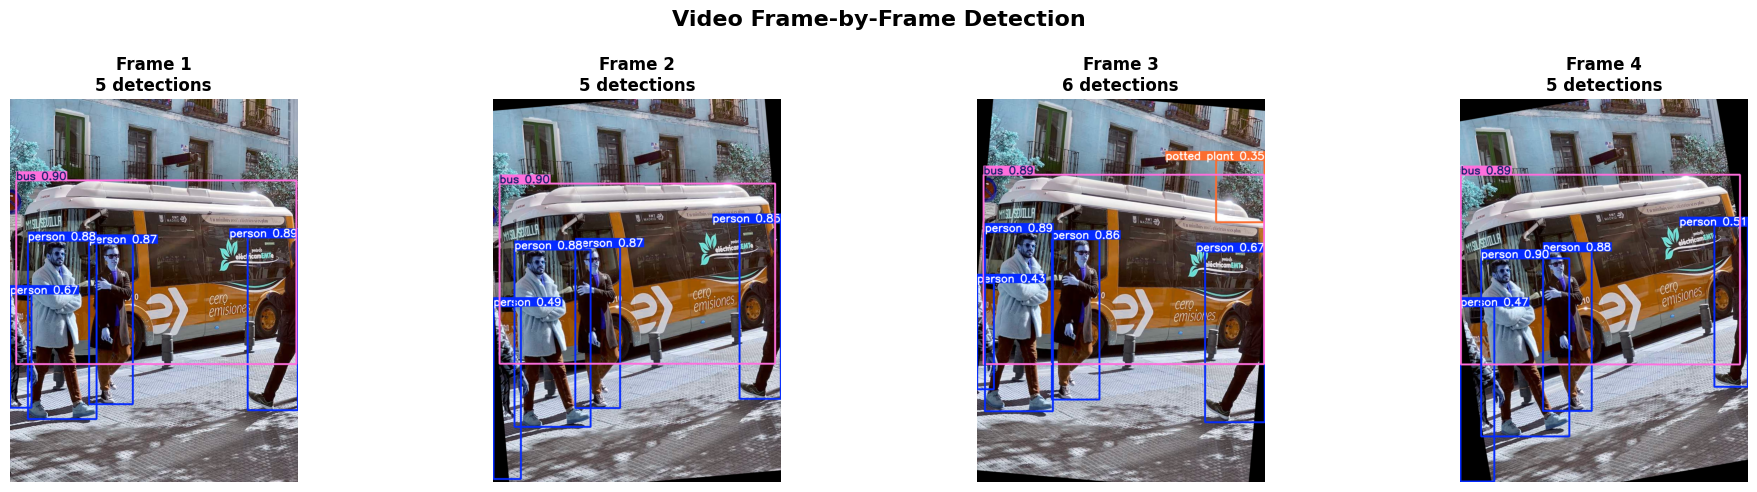

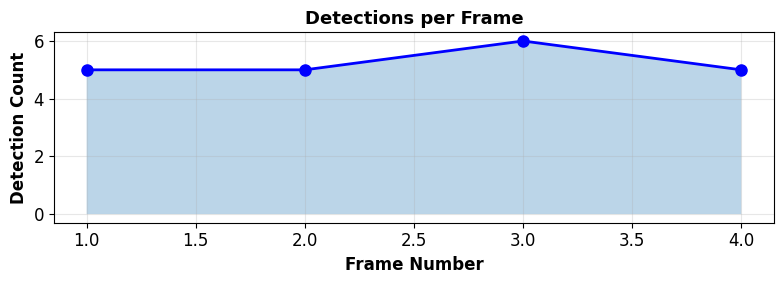

In [24]:
def process_video(video_path, model, output_path='output_video.mp4', max_frames=100):
    """video ke har frame pe YOLO detection chalata hai"""
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print(f"Video nahi khul saki: {video_path}")
        return [], []
    
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"Video Info: {width}x{height} @ {fps}fps | Total Frames: {total_frames}")
    
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))
    
    sample_frames = []
    frame_stats = []
    frame_count = 0
    
    while cap.isOpened() and frame_count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        
        results = model(frame, conf=0.25, verbose=False)
        annotated = results[0].plot()
        out.write(annotated)
        
        n_det = len(results[0].boxes)
        frame_stats.append(n_det)
        
        if frame_count % (max_frames // min(4, max_frames)) == 0:
            sample_frames.append(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        
        frame_count += 1
    
    cap.release()
    out.release()
    print(f"{frame_count} frames process ho gayi → Saved: {output_path}")
    return sample_frames, frame_stats

# video nahi hai toh image ko rotate kar ke frames simulate karte hain
print("Demo: Image augmentations se video frames simulate kar rahe hain")
print("(Production mein actual video file ka path do)\n")

sample_frames = []
frame_detections = []

for i, angle in enumerate([0, 5, -5, 10]):
    img = img_rgb.copy()
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1.0)
    rotated = cv2.warpAffine(img, M, (w, h))
    
    res = model(rotated, conf=0.25, verbose=False)[0]
    annotated = res.plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    
    sample_frames.append(annotated_rgb)
    frame_detections.append(len(res.boxes))

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for idx, (frame, n_det) in enumerate(zip(sample_frames, frame_detections)):
    axes[idx].imshow(frame)
    axes[idx].set_title(f'Frame {idx+1}\n{n_det} detections', fontsize=12, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Video Frame-by-Frame Detection', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# har frame mein kitne objects detect huay
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, len(frame_detections)+1), frame_detections, 'bo-', linewidth=2, markersize=8)
ax.fill_between(range(1, len(frame_detections)+1), frame_detections, alpha=0.3)
ax.set_xlabel('Frame Number', fontweight='bold')
ax.set_ylabel('Detection Count', fontweight='bold')
ax.set_title('Detections per Frame', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluation Metrics  IoU, Precision, Recall, mAP

Object detection mein yeh important metrics hain:
- **IoU (Intersection over Union)** — predicted aur actual box ka overlap. IoU > 0.5 matlab sahi detection hai
- **Precision** jo predict kiya usme se kitne sahi thay? $\text{Precision} = \frac{TP}{TP + FP}$
- **Recall**  jo actually thay unme se kitne dhoond liye? $\text{Recall} = \frac{TP}{TP + FN}$
- **mAP**  saari classes ka average AP. Yeh gold standard metric hai

Predicted Box:    [50, 50, 200, 200]
Ground Truth Box: [60, 55, 210, 210]
IoU Score:        0.7976 (79.8%)
Status: CORRECT (IoU >= 0.5)


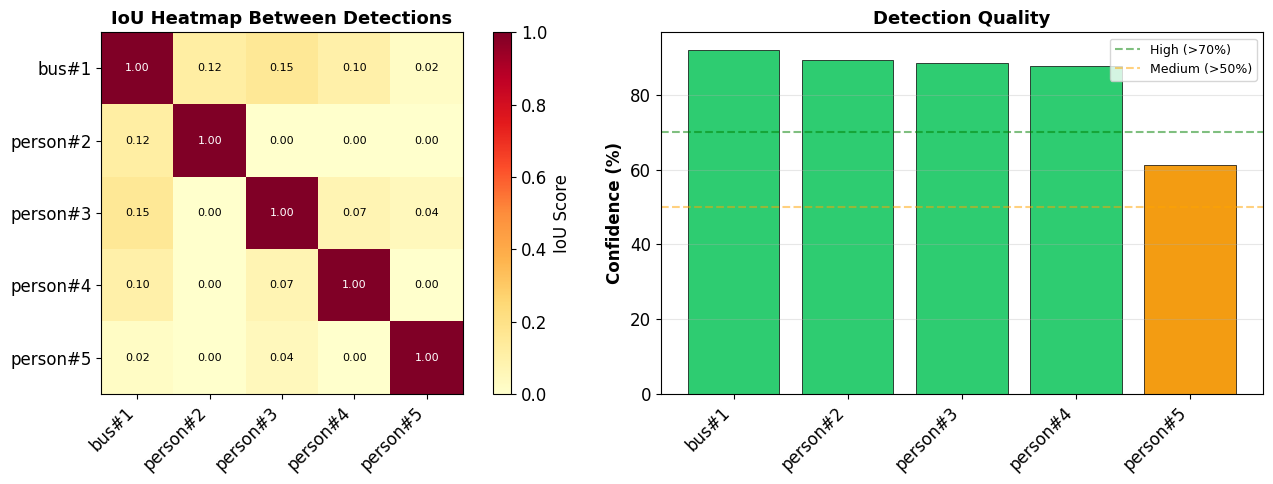


Mean Confidence: 83.8%
High (>70%): 4 | Medium (50-70%): 1 | Low (<50%): 0


In [25]:
def calculate_iou(box1, box2):
    """do boxes ke beech IoU calculate karta hai — overlap / union"""
    x1_inter = max(box1[0], box2[0])
    y1_inter = max(box1[1], box2[1])
    x2_inter = min(box1[2], box2[2])
    y2_inter = min(box1[3], box2[3])
    
    inter_width = max(0, x2_inter - x1_inter)
    inter_height = max(0, y2_inter - y1_inter)
    intersection = inter_width * inter_height
    
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    
    if union == 0:
        return 0.0
    return intersection / union


def compute_precision_recall(pred_boxes, gt_boxes, iou_threshold=0.5):
    """predicted aur ground truth boxes se precision recall nikalta hai"""
    tp = 0
    fp = 0
    matched_gt = set()
    
    for pred in pred_boxes:
        best_iou = 0
        best_gt_idx = -1
        
        for gt_idx, gt in enumerate(gt_boxes):
            iou = calculate_iou(pred, gt)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx
        
        if best_iou >= iou_threshold and best_gt_idx not in matched_gt:
            tp += 1
            matched_gt.add(best_gt_idx)
        else:
            fp += 1
    
    fn = len(gt_boxes) - tp
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    return precision, recall, tp, fp, fn


# IoU ka demo dekhte hain
demo_pred = [50, 50, 200, 200]
demo_gt   = [60, 55, 210, 210]

iou_score = calculate_iou(demo_pred, demo_gt)
print(f"Predicted Box:    {demo_pred}")
print(f"Ground Truth Box: {demo_gt}")
print(f"IoU Score:        {iou_score:.4f} ({iou_score*100:.1f}%)")
print(f"Status: {'CORRECT (IoU >= 0.5)' if iou_score >= 0.5 else 'INCORRECT (IoU < 0.5)'}")

# saari detections ke beech IoU matrix banate hain
n_boxes = len(bbox_xyxy)
iou_matrix = np.zeros((n_boxes, n_boxes))
for i in range(n_boxes):
    for j in range(n_boxes):
        iou_matrix[i][j] = calculate_iou(bbox_xyxy[i], bbox_xyxy[j])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# IoU Heatmap
im = axes[0].imshow(iou_matrix, cmap='YlOrRd', vmin=0, vmax=1)
axes[0].set_xticks(range(n_boxes))
axes[0].set_yticks(range(n_boxes))
axes[0].set_xticklabels([f'{class_labels[i][:6]}#{i+1}' for i in range(n_boxes)], rotation=45, ha='right')
axes[0].set_yticklabels([f'{class_labels[i][:6]}#{i+1}' for i in range(n_boxes)])
axes[0].set_title('IoU Heatmap Between Detections', fontsize=13, fontweight='bold')
plt.colorbar(im, ax=axes[0], label='IoU Score')

for i in range(n_boxes):
    for j in range(n_boxes):
        if n_boxes <= 10:
            axes[0].text(j, i, f'{iou_matrix[i,j]:.2f}', ha='center', va='center', 
                        fontsize=8, color='white' if iou_matrix[i,j] > 0.5 else 'black')

# confidence quality bar chart
axes[1].bar(range(n_boxes), confidences * 100,
            color=['#2ecc71' if c > 0.7 else '#f39c12' if c > 0.5 else '#e74c3c' for c in confidences],
            edgecolor='black', linewidth=0.5)
axes[1].set_xticks(range(n_boxes))
axes[1].set_xticklabels([f'{class_labels[i][:6]}#{i+1}' for i in range(n_boxes)], rotation=45, ha='right')
axes[1].set_ylabel('Confidence (%)', fontweight='bold')
axes[1].set_title('Detection Quality', fontsize=13, fontweight='bold')
axes[1].axhline(y=70, color='green', linestyle='--', alpha=0.5, label='High (>70%)')
axes[1].axhline(y=50, color='orange', linestyle='--', alpha=0.5, label='Medium (>50%)')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(f"\nMean Confidence: {confidences.mean()*100:.1f}%")
print(f"High (>70%): {sum(confidences > 0.7)} | Medium (50-70%): {sum((confidences > 0.5) & (confidences <= 0.7))} | Low (<50%): {sum(confidences <= 0.5)}")

## Gradio se interactive UI banate hain — image upload karo, detection dekho

In [26]:
import gradio as gr

yolo_model = YOLO('yolov8s.pt')

def detect_objects(image, conf_threshold, iou_threshold):
    """image pe detection chala ke annotated image, table aur summary return karta hai"""
    if image is None:
        return None, "<p>Pehle image upload karo</p>", "No image"
    
    results = yolo_model(image, conf=conf_threshold, iou=iou_threshold, verbose=False)
    result = results[0]
    
    annotated = result.plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    
    boxes = result.boxes
    n_detections = len(boxes)
    
    if n_detections == 0:
        return Image.fromarray(annotated_rgb), "<p style='text-align:center; font-size:18px;'>Koi object nahi mila is confidence level pe</p>", "0 objects"
    
    bbox_xyxy = boxes.xyxy.cpu().numpy()
    confs = boxes.conf.cpu().numpy()
    cls_ids = boxes.cls.cpu().numpy().astype(int)
    
    table_html = """
    <table style='width:100%; border-collapse: collapse; font-family: Arial;'>
        <thead><tr style='background: linear-gradient(135deg, #667eea 0%, #764ba2 100%); color: white;'>
            <th style='padding: 10px; border: 1px solid #ddd;'>#</th>
            <th style='padding: 10px; border: 1px solid #ddd;'>Class</th>
            <th style='padding: 10px; border: 1px solid #ddd;'>Confidence</th>
            <th style='padding: 10px; border: 1px solid #ddd;'>Bbox</th>
            <th style='padding: 10px; border: 1px solid #ddd;'>Size</th>
        </tr></thead><tbody>
    """
    
    for i in range(n_detections):
        conf_color = '#27ae60' if confs[i] > 0.7 else '#f39c12' if confs[i] > 0.5 else '#e74c3c'
        x1, y1, x2, y2 = bbox_xyxy[i].astype(int)
        table_html += f"""
            <tr style='background-color: {"#f8f9fa" if i % 2 == 0 else "#fff"}; text-align: center;'>
                <td style='padding: 8px; border: 1px solid #ddd;'>{i+1}</td>
                <td style='padding: 8px; border: 1px solid #ddd; font-weight: bold;'>{yolo_model.names[cls_ids[i]]}</td>
                <td style='padding: 8px; border: 1px solid #ddd;'>
                    <span style='background-color: {conf_color}; color: white; padding: 3px 8px; border-radius: 12px;'>{confs[i]*100:.1f}%</span>
                </td>
                <td style='padding: 8px; border: 1px solid #ddd; font-family: monospace;'>({x1}, {y1}, {x2}, {y2})</td>
                <td style='padding: 8px; border: 1px solid #ddd;'>{x2-x1}x{y2-y1}px</td>
            </tr>"""
    
    table_html += "</tbody></table>"
    
    classes_found = list(set([yolo_model.names[c] for c in cls_ids]))
    summary = f"{n_detections} object(s) | Classes: {', '.join(classes_found)} | Avg Conf: {confs.mean()*100:.1f}% | {result.speed['inference']:.1f}ms"
    
    return Image.fromarray(annotated_rgb), table_html, summary

print("Detection function ready hai!")

Detection function ready hai!


## Advanced Gradio UI — confidence slider, class filter, JSON output, modern styling

In [27]:
custom_css = """
.gradio-container { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif !important; }
.gr-button-primary { background: linear-gradient(135deg, #667eea 0%, #764ba2 100%) !important; border: none !important; font-weight: bold !important; font-size: 16px !important; }
.gr-button-primary:hover { background: linear-gradient(135deg, #764ba2 0%, #667eea 100%) !important; transform: scale(1.02); }
h1 { text-align: center !important; background: linear-gradient(135deg, #667eea 0%, #764ba2 100%); -webkit-background-clip: text; -webkit-text-fill-color: transparent; font-size: 2.5em !important; }
.footer { text-align: center; margin-top: 20px; color: #888; font-size: 14px; }
"""

def detect_with_filters(image, conf_threshold, iou_threshold, selected_classes):
    """class filter ke saath detection — zyada control milta hai"""
    if image is None:
        return None, "<p>Image upload karo pehle</p>", "No image", {}
    
    results = yolo_model(image, conf=conf_threshold, iou=iou_threshold, verbose=False)
    result = results[0]
    
    boxes = result.boxes
    bbox_xyxy = boxes.xyxy.cpu().numpy()
    confs = boxes.conf.cpu().numpy()
    cls_ids = boxes.cls.cpu().numpy().astype(int)
    
    if selected_classes and len(selected_classes) > 0:
        mask = [yolo_model.names[c] in selected_classes for c in cls_ids]
        bbox_xyxy = bbox_xyxy[mask]
        confs = confs[mask]
        cls_ids = cls_ids[mask]
    
    img_array = np.array(image)
    annotated = draw_detections(img_array, bbox_xyxy, confs, cls_ids, yolo_model.names)
    
    n_det = len(confs)
    
    if n_det == 0:
        return Image.fromarray(img_array), "<p>Koi detection nahi mila filters ke saath</p>", "0 objects", {}
    
    table_html = """
    <table style='width:100%; border-collapse: collapse; font-size: 14px;'>
        <thead><tr style='background: linear-gradient(135deg, #667eea 0%, #764ba2 100%); color: white;'>
            <th style='padding: 10px;'>#</th><th style='padding: 10px;'>Class</th>
            <th style='padding: 10px;'>Confidence</th><th style='padding: 10px;'>BBox</th>
            <th style='padding: 10px;'>Size (WxH)</th>
        </tr></thead><tbody>
    """
    
    json_data = {"detections": [], "total": n_det, "inference_ms": result.speed['inference']}
    
    for i in range(n_det):
        x1, y1, x2, y2 = bbox_xyxy[i].astype(int)
        cls_name = yolo_model.names[cls_ids[i]]
        conf_pct = confs[i] * 100
        conf_color = '#27ae60' if confs[i] > 0.7 else '#f39c12' if confs[i] > 0.5 else '#e74c3c'
        
        table_html += f"""
        <tr style='background:{"#f8f9fa" if i%2==0 else "#fff"}; text-align:center;'>
            <td style='padding:8px;'>{i+1}</td>
            <td style='padding:8px; font-weight:bold;'>{cls_name}</td>
            <td style='padding:8px;'><span style='background:{conf_color};color:white;padding:3px 10px;border-radius:12px;'>{conf_pct:.1f}%</span></td>
            <td style='padding:8px; font-family:monospace;'>({x1},{y1},{x2},{y2})</td>
            <td style='padding:8px;'>{x2-x1}x{y2-y1}</td>
        </tr>"""
        
        json_data["detections"].append({
            "id": i+1, "class": cls_name, 
            "confidence": round(float(confs[i]), 4),
            "bbox": {"x1": int(x1), "y1": int(y1), "x2": int(x2), "y2": int(y2)},
            "size": {"width": int(x2-x1), "height": int(y2-y1)}
        })
    
    table_html += "</tbody></table>"
    classes_found = list(set([yolo_model.names[c] for c in cls_ids]))
    summary = f"{n_det} object(s): {', '.join(classes_found)} | Avg Conf: {confs.mean()*100:.1f}%"
    
    return Image.fromarray(annotated), table_html, summary, json_data


# Gradio Blocks UI
with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as demo:
    
    gr.HTML("""
        <h1>YOLOv8 Object Detection</h1>
        <p style='text-align:center; font-size:16px; color:#666;'>
            Image upload karo aur real-time mein objects detect karo YOLOv8 CNN se.<br>
            Confidence threshold adjust karo aur classes filter karo.
        </p>
    """)
    
    with gr.Row():
        with gr.Column(scale=1):
            input_image = gr.Image(type="pil", label="Upload Image", height=400)
            with gr.Row():
                conf_slider = gr.Slider(minimum=0.1, maximum=1.0, value=0.25, step=0.05,
                    label="Confidence Threshold", info="Minimum score for detection")
                iou_slider = gr.Slider(minimum=0.1, maximum=1.0, value=0.45, step=0.05,
                    label="IoU Threshold (NMS)", info="NMS overlap threshold")
            class_filter = gr.Dropdown(choices=list(yolo_model.names.values()),
                multiselect=True, label="Filter Classes (khali chhoro sab ke liye)",
                info="Specific classes select karo")
            detect_btn = gr.Button("Detect Objects", variant="primary", size="lg")
        
        with gr.Column(scale=1):
            output_image = gr.Image(type="pil", label="Detection Results", height=400)
            summary_text = gr.Textbox(label="Summary", interactive=False)
    
    with gr.Row():
        with gr.Column(scale=2):
            results_html = gr.HTML(label="Detection Details")
        with gr.Column(scale=1):
            json_output = gr.JSON(label="Raw JSON Data")
    
    gr.Examples(
        examples=[['sample_images/street.jpg', 0.25, 0.45, []], ['sample_images/zidane.jpg', 0.30, 0.45, []]],
        inputs=[input_image, conf_slider, iou_slider, class_filter],
        outputs=[output_image, results_html, summary_text, json_output],
        fn=detect_with_filters, cache_examples=False, label="Example Images"
    )
    
    detect_btn.click(fn=detect_with_filters,
        inputs=[input_image, conf_slider, iou_slider, class_filter],
        outputs=[output_image, results_html, summary_text, json_output])
    
    gr.HTML("""<div class='footer'>
        <p>YOLOv8 + Gradio | CNN-Based Object Detection</p>
        <p>Model: YOLOv8s | Dataset: COCO (80 classes) | Ultralytics</p>
    </div>""")

print("Gradio app ban gayi hai! Agla cell run karo launch ke liye.")

Gradio app ban gayi hai! Agla cell run karo launch ke liye.


In [ ]:
# Gradio app launch kar rahe hain notebook mein
# demo.launch(share=True)  # public URL chahiye toh uncomment karo
demo.launch(inline=True, share=False)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
